In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
from pathlib import Path

DATA_PATH = Path(r"D:\Ashraf\Projects\MIMIC-IV Healthcare Analytics\Data\hosp")

print(DATA_PATH)

D:\Ashraf\Projects\MIMIC-IV Healthcare Analytics\Data\hosp


In [4]:
files = list(DATA_PATH.iterdir())

for file in files:
    print(file.name)

admissions.csv.gz
diagnoses_icd.csv.gz
d_icd_diagnoses.csv.gz
patients.csv.gz
prescriptions.csv.gz


In [5]:
patients = pd.read_csv(
    DATA_PATH / "patients.csv.gz"
)

patients.head()

,subject_id,gender,anchor_age,anchor_year,anchor_year_group,dod
0,10014729,F,21,2125,2011 - 2013,NaN
1,10003400,F,72,2134,2011 - 2013,2137-09-02
2,10002428,F,80,2155,2011 - 2013,NaN
3,10032725,F,38,2143,2011 - 2013,2143-03-30
4,10027445,F,48,2142,2011 - 2013,2146-02-09


In [6]:
admissions = pd.read_csv(
    DATA_PATH / "admissions.csv.gz"
)

admissions.head()

,subject_id,hadm_id,admittime,dischtime,deathtime,admission_type,admit_provider_id,admission_location,discharge_location,insurance,language,marital_status,race,edregtime,edouttime,hospital_expire_flag
0,10004235,24181354,2196-02-24 14:38:00,2196-03-04 14:02:00,NaN,URGENT,P03YMR,TRANSFER FROM HOSPITAL,SKILLED NURSING FACILITY,Medicaid,ENGLISH,SINGLE,BLACK/CAPE VERDEAN,2196-02-24 12:15:00,2196-02-24 17:07:00,0
1,10009628,25926192,2153-09-17 17:08:00,2153-09-25 13:20:00,NaN,URGENT,P41R5N,TRANSFER FROM HOSPITAL,HOME HEALTH CARE,Medicaid,?,MARRIED,HISPANIC/LATINO - PUERTO RICAN,NaN,NaN,0
2,10018081,23983182,2134-08-18 02:02:00,2134-08-23 19:35:00,NaN,URGENT,P233F6,TRANSFER FROM HOSPITAL,SKILLED NURSING FACILITY,Medicare,ENGLISH,MARRIED,WHITE,2134-08-17 16:24:00,2134-08-18 03:15:00,0
3,10006053,22942076,2111-11-13 23:39:00,2111-11-15 17:20:00,2111-11-15 17:20:00,URGENT,P38TI6,TRANSFER FROM HOSPITAL,DIED,Medicaid,ENGLISH,NaN,UNKNOWN,NaN,NaN,1
4,10031404,21606243,2113-08-04 18:46:00,2113-08-06 20:57:00,NaN,URGENT,P07HDB,TRANSFER FROM HOSPITAL,HOME,Other,ENGLISH,WIDOWED,WHITE,NaN,NaN,0


In [7]:
print("Patients:", patients.shape)
print("Admissions:", admissions.shape)

Patients: (100, 6)
Admissions: (275, 16)


# Patient Records Analysis

In [8]:
print("Patient columns:")
print(patients.columns.tolist())

Patient columns:
['subject_id', 'gender', 'anchor_age', 'anchor_year', 'anchor_year_group', 'dod']


In [9]:
patients.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 6 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   subject_id         100 non-null    int64 
 1   gender             100 non-null    object
 2   anchor_age         100 non-null    int64 
 3   anchor_year        100 non-null    int64 
 4   anchor_year_group  100 non-null    object
 5   dod                31 non-null     object
dtypes: int64(3), object(3)
memory usage: 4.8+ KB


In [10]:
patients.head(10)

,subject_id,gender,anchor_age,anchor_year,anchor_year_group,dod
0,10014729,F,21,2125,2011 - 2013,NaN
1,10003400,F,72,2134,2011 - 2013,2137-09-02
2,10002428,F,80,2155,2011 - 2013,NaN
3,10032725,F,38,2143,2011 - 2013,2143-03-30
4,10027445,F,48,2142,2011 - 2013,2146-02-09
5,10037928,F,78,2175,2011 - 2013,NaN
6,10001725,F,46,2110,2011 - 2013,NaN
7,10040025,F,64,2143,2011 - 2013,2148-02-07
8,10008454,F,26,2110,2011 - 2013,NaN
9,10020640,F,91,2153,2011 - 2013,2154-02-04


In [11]:
print("Total patient records:", len(patients))
print("Unique patients:", patients["subject_id"].nunique())
print("Male patients:", (patients["gender"] == "M").sum())
print("Female patients:", (patients["gender"] == "F").sum())

Total patient records: 100
Unique patients: 100
Male patients: 57
Female patients: 43


In [12]:
patients["anchor_age"].describe()

count    100.00000
mean      61.75000
std       16.16979
min       21.00000
25%       51.75000
50%       63.00000
75%       72.00000
max       91.00000
Name: anchor_age, dtype: float64

In [13]:
gender_counts = patients["gender"].value_counts()

gender_counts

gender
M    57
F    43
Name: count, dtype: int64

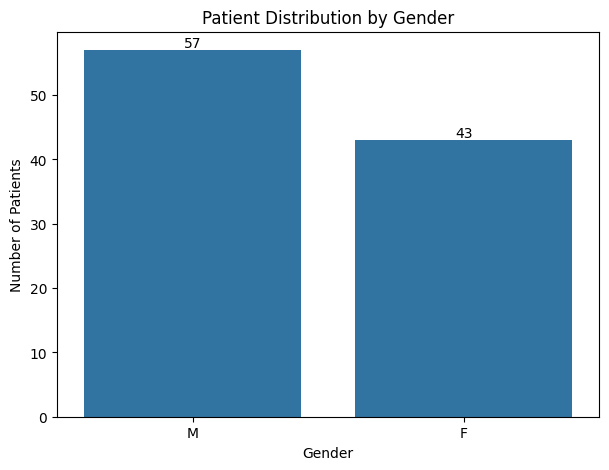

In [14]:
plt.figure(figsize=(7, 5))

order = patients["gender"].value_counts().index

ax = sns.countplot(
    data=patients,
    x="gender",
    order=order
)

ax.bar_label(ax.containers[0])

plt.title("Patient Distribution by Gender")
plt.xlabel("Gender")
plt.ylabel("Number of Patients")

plt.show()

# Admission Records Analysis

In [15]:
admissions.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 275 entries, 0 to 274
Data columns (total 16 columns):
 #   Column                Non-Null Count  Dtype 
---  ------                --------------  ----- 
 0   subject_id            275 non-null    int64 
 1   hadm_id               275 non-null    int64 
 2   admittime             275 non-null    object
 3   dischtime             275 non-null    object
 4   deathtime             15 non-null     object
 5   admission_type        275 non-null    object
 6   admit_provider_id     275 non-null    object
 7   admission_location    275 non-null    object
 8   discharge_location    233 non-null    object
 9   insurance             275 non-null    object
 10  language              275 non-null    object
 11  marital_status        263 non-null    object
 12  race                  275 non-null    object
 13  edregtime             182 non-null    object
 14  edouttime             182 non-null    object
 15  hospital_expire_flag  275 non-null    in

In [16]:
admissions.head()

,subject_id,hadm_id,admittime,dischtime,deathtime,admission_type,admit_provider_id,admission_location,discharge_location,insurance,language,marital_status,race,edregtime,edouttime,hospital_expire_flag
0,10004235,24181354,2196-02-24 14:38:00,2196-03-04 14:02:00,NaN,URGENT,P03YMR,TRANSFER FROM HOSPITAL,SKILLED NURSING FACILITY,Medicaid,ENGLISH,SINGLE,BLACK/CAPE VERDEAN,2196-02-24 12:15:00,2196-02-24 17:07:00,0
1,10009628,25926192,2153-09-17 17:08:00,2153-09-25 13:20:00,NaN,URGENT,P41R5N,TRANSFER FROM HOSPITAL,HOME HEALTH CARE,Medicaid,?,MARRIED,HISPANIC/LATINO - PUERTO RICAN,NaN,NaN,0
2,10018081,23983182,2134-08-18 02:02:00,2134-08-23 19:35:00,NaN,URGENT,P233F6,TRANSFER FROM HOSPITAL,SKILLED NURSING FACILITY,Medicare,ENGLISH,MARRIED,WHITE,2134-08-17 16:24:00,2134-08-18 03:15:00,0
3,10006053,22942076,2111-11-13 23:39:00,2111-11-15 17:20:00,2111-11-15 17:20:00,URGENT,P38TI6,TRANSFER FROM HOSPITAL,DIED,Medicaid,ENGLISH,NaN,UNKNOWN,NaN,NaN,1
4,10031404,21606243,2113-08-04 18:46:00,2113-08-06 20:57:00,NaN,URGENT,P07HDB,TRANSFER FROM HOSPITAL,HOME,Other,ENGLISH,WIDOWED,WHITE,NaN,NaN,0


In [17]:
print("Total admission records:", len(admissions))
print("Unique admissions:", admissions["hadm_id"].nunique())
print("Unique patients admitted:", admissions["subject_id"].nunique())

Total admission records: 275
Unique admissions: 275
Unique patients admitted: 100


In [18]:
admissions_per_patient = (
    admissions
    .groupby("subject_id")
    .size()
    .reset_index(name="admission_count")
)

admissions_per_patient.head()

,subject_id,admission_count
0,10000032,4
1,10001217,2
2,10001725,1
3,10002428,7
4,10002495,1


In [19]:
admissions_per_patient["admission_count"].describe()

count    100.0000
mean       2.7500
std        3.1794
min        1.0000
25%        1.0000
50%        1.0000
75%        3.0000
max       20.0000
Name: admission_count, dtype: float64

In [20]:
admissions["admission_type"].value_counts()

admission_type
EW EMER.                       104
OBSERVATION ADMIT               45
URGENT                          38
EU OBSERVATION                  30
SURGICAL SAME DAY ADMISSION     18
DIRECT EMER.                    15
ELECTIVE                        13
DIRECT OBSERVATION               7
AMBULATORY OBSERVATION           5
Name: count, dtype: int64

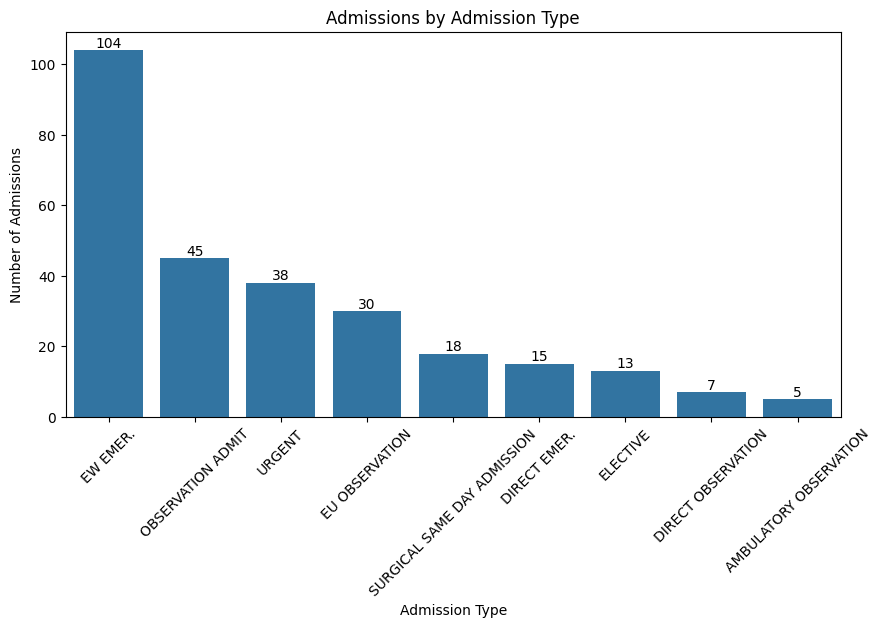

In [21]:
plt.figure(figsize=(10, 5))

order = admissions["admission_type"].value_counts().index

ax = sns.countplot(
    data=admissions,
    x="admission_type",
    order=order
)

ax.bar_label(ax.containers[0])

plt.title("Admissions by Admission Type")
plt.xlabel("Admission Type")
plt.ylabel("Number of Admissions")

plt.xticks(rotation=45)

plt.show()

In [22]:
admissions["admission_location"].value_counts()

admission_location
EMERGENCY ROOM                            134
PHYSICIAN REFERRAL                         63
TRANSFER FROM HOSPITAL                     43
CLINIC REFERRAL                            10
PROCEDURE SITE                              7
WALK-IN/SELF REFERRAL                       7
TRANSFER FROM SKILLED NURSING FACILITY      4
PACU                                        4
INTERNAL TRANSFER TO OR FROM PSYCH          2
INFORMATION NOT AVAILABLE                   1
Name: count, dtype: int64

In [23]:
admissions["discharge_location"].value_counts()

discharge_location
HOME HEALTH CARE                76
HOME                            72
SKILLED NURSING FACILITY        36
DIED                            15
REHAB                           13
CHRONIC/LONG TERM ACUTE CARE     9
HOSPICE                          5
AGAINST ADVICE                   4
PSYCH FACILITY                   2
ACUTE HOSPITAL                   1
Name: count, dtype: int64

In [24]:
admissions["insurance"].value_counts()

insurance
Other       149
Medicare    104
Medicaid     22
Name: count, dtype: int64

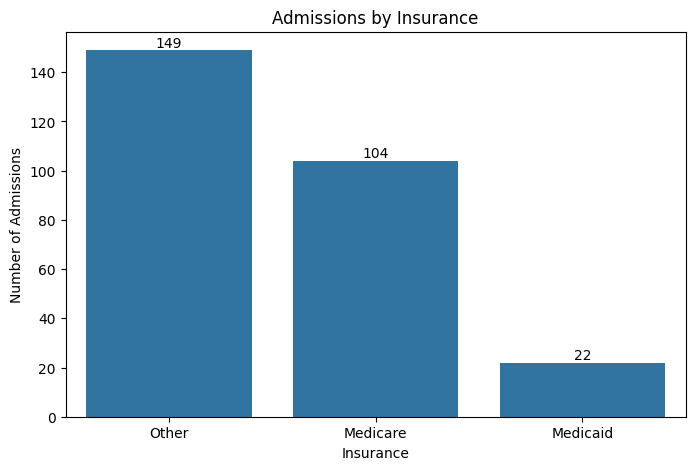

In [25]:
plt.figure(figsize=(8, 5))

order = admissions["insurance"].value_counts().index

ax = sns.countplot(
    data=admissions,
    x="insurance",
    order=order
)

ax.bar_label(ax.containers[0])

plt.title("Admissions by Insurance")
plt.xlabel("Insurance")
plt.ylabel("Number of Admissions")

plt.show()

# Diagnosis Records Analysis

In [26]:
diagnoses = pd.read_csv(
    DATA_PATH / "diagnoses_icd.csv.gz"
)

diagnoses.head()

,subject_id,hadm_id,seq_num,icd_code,icd_version
0,10035185,22580999,3,4139,9
1,10035185,22580999,10,V707,9
2,10035185,22580999,1,41401,9
3,10035185,22580999,9,3899,9
4,10035185,22580999,11,V8532,9


In [27]:
print("Diagnosis records:", len(diagnoses))
print("Unique patients:", diagnoses["subject_id"].nunique())
print("Unique admissions:", diagnoses["hadm_id"].nunique())
print("Unique ICD codes:", diagnoses["icd_code"].nunique())

Diagnosis records: 4506
Unique patients: 100
Unique admissions: 275
Unique ICD codes: 1472


In [28]:
d_icd_diagnoses = pd.read_csv(
    DATA_PATH / "d_icd_diagnoses.csv.gz"
)

d_icd_diagnoses.head()

,icd_code,icd_version,long_title
0,0090,9,"Infectious colitis, enteritis, and gastroenter..."
1,01160,9,"Tuberculous pneumonia [any form], unspecified"
2,01186,9,"Other specified pulmonary tuberculosis, tuberc..."
3,01200,9,"Tuberculous pleurisy, unspecified"
4,01236,9,"Tuberculous laryngitis, tubercle bacilli not f..."


In [29]:
diagnoses["icd_version"].value_counts()

icd_version
10    2313
9     2193
Name: count, dtype: int64

In [30]:
diagnosis_counts = diagnoses["icd_code"].value_counts().head(10)

diagnosis_counts

icd_code
4019      68
E785      57
2724      55
E039      47
Z794      37
Z87891    35
42731     34
25000     33
I2510     33
I10       32
Name: count, dtype: int64

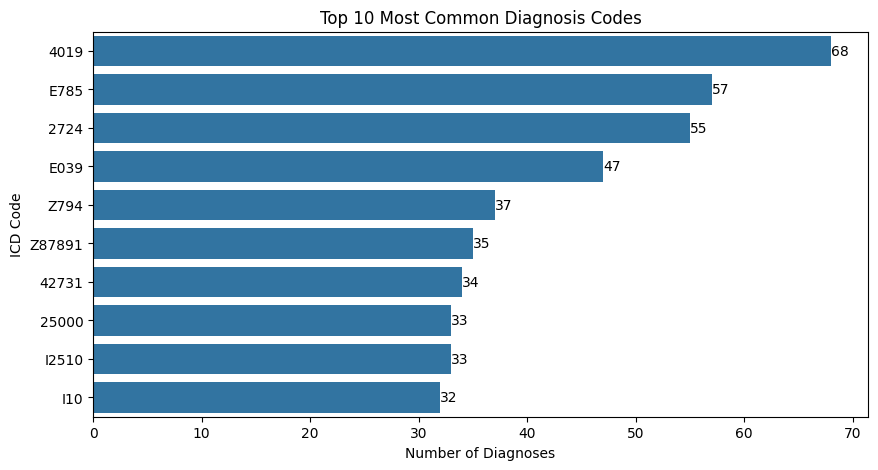

In [31]:
plt.figure(figsize=(10, 5))

ax = sns.barplot(
    x=diagnosis_counts.values,
    y=diagnosis_counts.index
)

ax.bar_label(ax.containers[0])

plt.title("Top 10 Most Common Diagnosis Codes")
plt.xlabel("Number of Diagnoses")
plt.ylabel("ICD Code")

plt.show()

In [32]:
d_icd_diagnoses.columns

Index(['icd_code', 'icd_version', 'long_title'], dtype='object')

In [33]:
diagnosis_data = diagnoses.merge(
    d_icd_diagnoses,
    on=["icd_code", "icd_version"],
    how="left"
)

In [34]:
diagnosis_data.head()

,subject_id,hadm_id,seq_num,icd_code,icd_version,long_title
0,10035185,22580999,3,4139,9,Other and unspecified angina pectoris
1,10035185,22580999,10,V707,9,Examination of participant in clinical trial
2,10035185,22580999,1,41401,9,Coronary atherosclerosis of native coronary ar...
3,10035185,22580999,9,3899,9,Unspecified hearing loss
4,10035185,22580999,11,V8532,9,"Body Mass Index 32.0-32.9, adult"


In [35]:
top_diagnoses = (
    diagnosis_data["long_title"]
    .value_counts()
    .head(10)
)

top_diagnoses

long_title
Unspecified essential hypertension             68
Hyperlipidemia, unspecified                    57
Acute kidney failure, unspecified              56
Other and unspecified hyperlipidemia           55
Hypothyroidism, unspecified                    47
Obesity, unspecified                           43
Anemia, unspecified                            41
Long term (current) use of insulin             37
Urinary tract infection, site not specified    36
Personal history of nicotine dependence        35
Name: count, dtype: int64

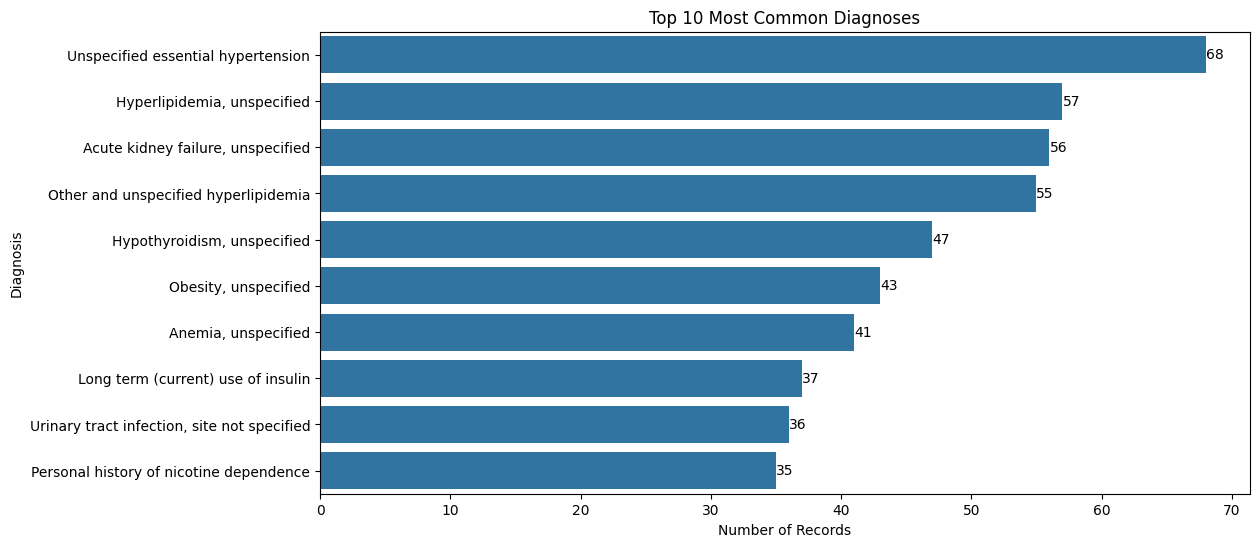

In [36]:
plt.figure(figsize=(12, 6))

ax = sns.barplot(
    x=top_diagnoses.values,
    y=top_diagnoses.index
)

ax.bar_label(ax.containers[0])

plt.title("Top 10 Most Common Diagnoses")
plt.xlabel("Number of Records")
plt.ylabel("Diagnosis")

plt.show()

In [37]:
diagnoses_per_admission = (
    diagnoses.groupby("hadm_id")
    .size()
)

diagnoses_per_admission.describe()

count    275.000000
mean      16.385455
std        9.014413
min        2.000000
25%        9.000000
50%       14.000000
75%       23.000000
max       39.000000
dtype: float64

In [38]:
print(
    "Average diagnoses per admission:",
    round(diagnoses_per_admission.mean(), 2)
)

Average diagnoses per admission: 16.39


In [39]:
diagnoses["seq_num"].value_counts().head(10)

seq_num
2     275
1     275
3     274
4     271
5     268
6     257
7     248
8     235
9     216
10    203
Name: count, dtype: int64

In [40]:
primary_diagnoses = diagnoses[
    diagnoses["seq_num"] == 1
]

In [41]:
print(
    "Primary diagnosis records:",
    len(primary_diagnoses)
)

Primary diagnosis records: 275


In [42]:
primary_diagnosis_data = primary_diagnoses.merge(
    d_icd_diagnoses,
    on=["icd_code", "icd_version"],
    how="left"
)

In [43]:
top_primary = (
    primary_diagnosis_data["long_title"]
    .value_counts()
    .head(10)
)

top_primary

long_title
Coronary atherosclerosis of native coronary artery    7
Acute kidney failure, unspecified                     7
Cerebral aneurysm, nonruptured                        4
Aortic valve disorders                                4
Non-ST elevation (NSTEMI) myocardial infarction       4
Other postoperative infection                         4
Abscess of liver                                      3
Sepsis, unspecified organism                          3
Acute on chronic diastolic heart failure              3
Other encephalopathy                                  3
Name: count, dtype: int64

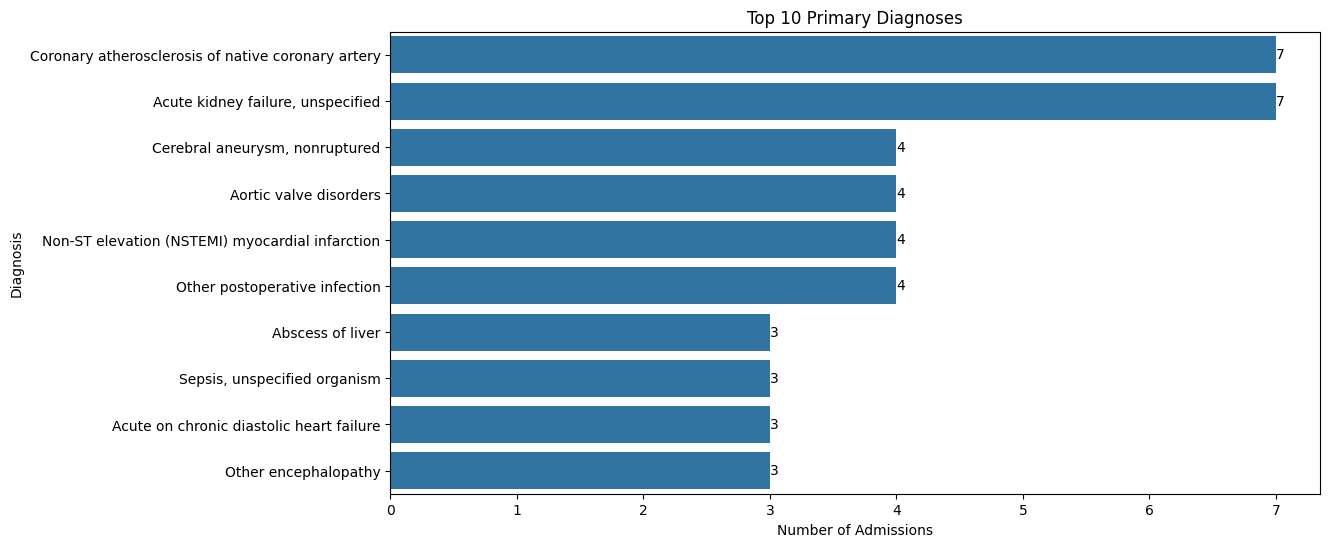

In [44]:
plt.figure(figsize=(12, 6))

ax = sns.barplot(
    x=top_primary.values,
    y=top_primary.index
)

ax.bar_label(ax.containers[0])

plt.title("Top 10 Primary Diagnoses")
plt.xlabel("Number of Admissions")
plt.ylabel("Diagnosis")

plt.show()

# Treatment Records Analysis

In [45]:
prescriptions = pd.read_csv(
    DATA_PATH / "prescriptions.csv.gz"
)

prescriptions.head()

,subject_id,hadm_id,pharmacy_id,poe_id,poe_seq,order_provider_id,starttime,stoptime,drug_type,drug,...,gsn,ndc,prod_strength,form_rx,dose_val_rx,dose_unit_rx,form_val_disp,form_unit_disp,doses_per_24_hrs,route
0,10027602,28166872,27168639,NaN,NaN,NaN,2201-10-30 12:00:00,NaN,MAIN,Fentanyl Citrate,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,10027602,28166872,40720238,NaN,NaN,NaN,2201-10-30 12:00:00,NaN,MAIN,Fentanyl Citrate,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,10027602,28166872,62845687,NaN,NaN,NaN,2201-10-31 12:00:00,NaN,MAIN,Lorazepam,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,10027602,28166872,24340150,NaN,NaN,NaN,2201-10-30 12:00:00,NaN,MAIN,Midazolam,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,10027602,28166872,14435820,NaN,NaN,NaN,2201-10-30 12:00:00,NaN,MAIN,Midazolam,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [46]:
prescriptions.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 18087 entries, 0 to 18086
Data columns (total 21 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   subject_id         18087 non-null  int64  
 1   hadm_id            18087 non-null  int64  
 2   pharmacy_id        18087 non-null  int64  
 3   poe_id             17969 non-null  object 
 4   poe_seq            17969 non-null  float64
 5   order_provider_id  17993 non-null  object 
 6   starttime          18087 non-null  object 
 7   stoptime           18073 non-null  object 
 8   drug_type          18087 non-null  object 
 9   drug               18087 non-null  object 
 10  formulary_drug_cd  18075 non-null  object 
 11  gsn                15568 non-null  object 
 12  ndc                18066 non-null  float64
 13  prod_strength      18078 non-null  object 
 14  form_rx            12 non-null     object 
 15  dose_val_rx        18078 non-null  object 
 16  dose_unit_rx       180

In [47]:
prescriptions.columns.tolist()

['subject_id',
 'hadm_id',
 'pharmacy_id',
 'poe_id',
 'poe_seq',
 'order_provider_id',
 'starttime',
 'stoptime',
 'drug_type',
 'drug',
 'formulary_drug_cd',
 'gsn',
 'ndc',
 'prod_strength',
 'form_rx',
 'dose_val_rx',
 'dose_unit_rx',
 'form_val_disp',
 'form_unit_disp',
 'doses_per_24_hrs',
 'route']

In [48]:
prescriptions_clean = prescriptions[
    [
        "subject_id",
        "hadm_id",
        "starttime",
        "stoptime",
        "drug",
        "drug_type",
        "dose_val_rx",
        "dose_unit_rx",
        "route"
    ]
]

In [49]:
print("Total medication records:", len(prescriptions_clean))
print("Unique patients:", prescriptions_clean["subject_id"].nunique())
print("Unique admissions:", prescriptions_clean["hadm_id"].nunique())
print("Unique medications:", prescriptions_clean["drug"].nunique())

Total medication records: 18087
Unique patients: 100
Unique admissions: 250
Unique medications: 631


In [50]:
top_medications = prescriptions_clean["drug"].value_counts().head(10)

top_medications

drug
Insulin                        915
0.9% Sodium Chloride           810
Potassium Chloride             610
Sodium Chloride 0.9%  Flush    585
Furosemide                     510
5% Dextrose                    492
Bag                            454
Magnesium Sulfate              402
Metoprolol Tartrate            371
Acetaminophen                  344
Name: count, dtype: int64

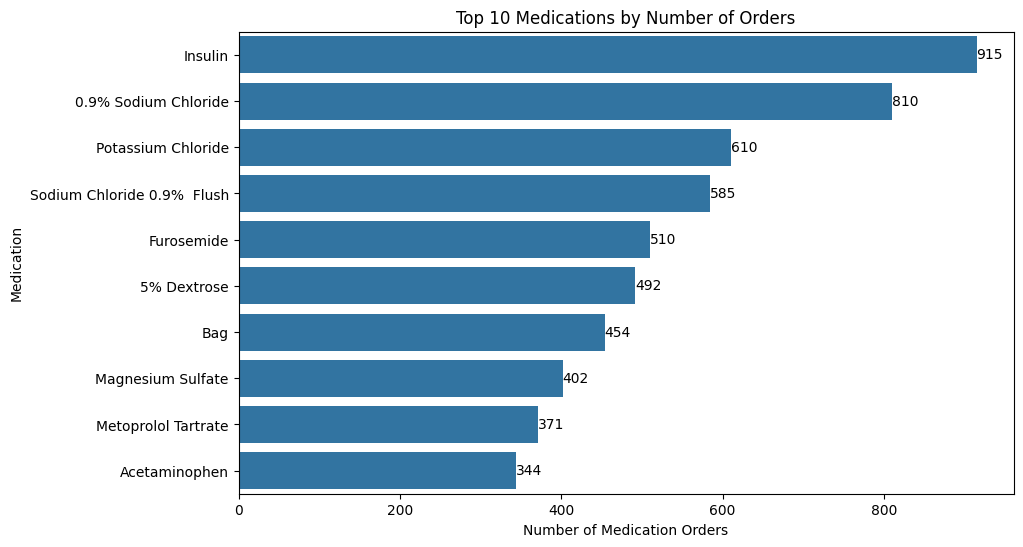

In [51]:
plt.figure(figsize=(10, 6))

ax = sns.barplot(x=top_medications.values,y=top_medications.index)

ax.bar_label(ax.containers[0])

plt.title("Top 10 Medications by Number of Orders")
plt.xlabel("Number of Medication Orders")
plt.ylabel("Medication")
plt.show()

In [52]:
route_counts = prescriptions_clean["route"].value_counts()

route_counts

route
IV             8219
PO/NG          3841
PO             2191
SC             1249
IV DRIP        1026
IM              370
IH              194
TP              157
PR              152
ORAL             77
TD               72
IVPCA            69
IV BOLUS         61
DWELL            56
NU               54
NG               45
BOTH EYES        39
NEB              33
DIALYS           33
REPLACE          32
ED               28
SL               23
ID               22
SUBCUT           11
LEFT EYE         11
PERIPHNERVE       4
VG                2
RIGHT EYE         2
LEFT EAR          2
RIGHT EAR         2
OS                1
IJ                1
NAS               1
BOTH EARS         1
Name: count, dtype: int64

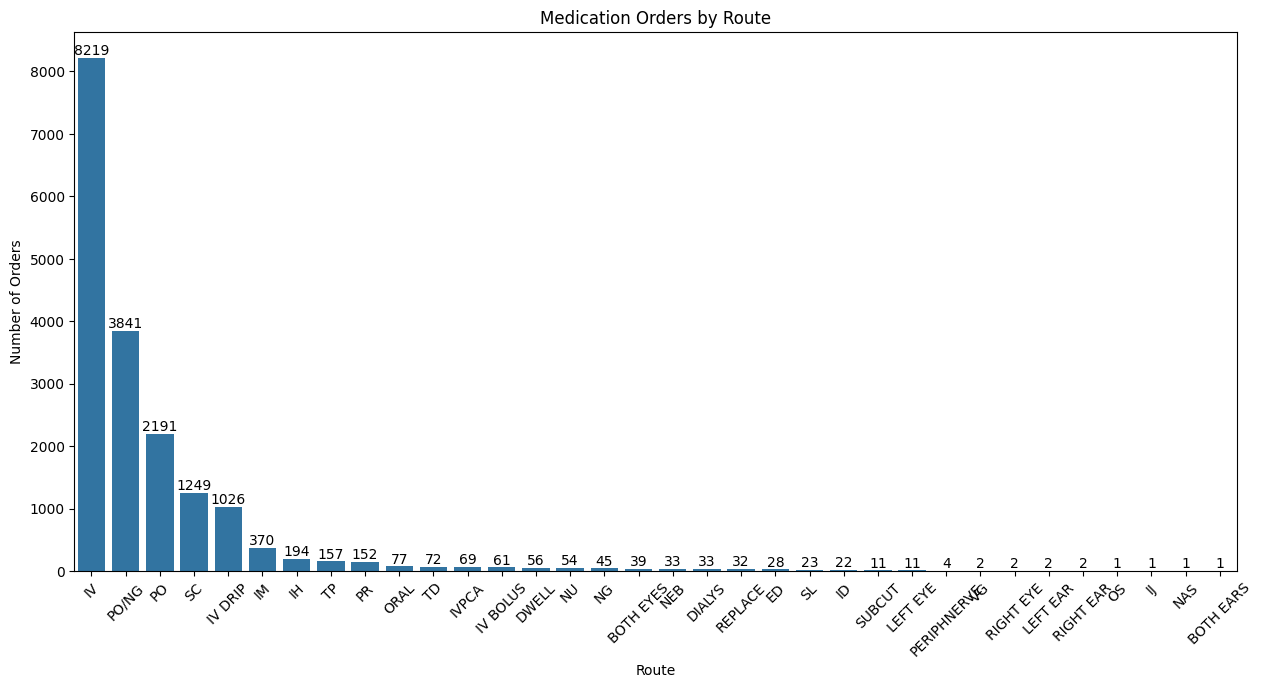

In [53]:
plt.figure(figsize=(15, 7))

ax = sns.barplot(
    x=route_counts.index,
    y=route_counts.values
)

ax.bar_label(ax.containers[0])

plt.title("Medication Orders by Route")
plt.xlabel("Route")
plt.ylabel("Number of Orders")
plt.xticks(rotation=45)
plt.show()

In [54]:
medications_per_admission = (
    prescriptions_clean
    .groupby("hadm_id")
    .size()
    .sort_values(ascending=False)
)

medications_per_admission.head(10)

hadm_id
23831430    348
29276678    331
22987108    320
28258130    314
23559586    249
28661809    241
20214994    227
25177949    214
23052851    212
28998349    211
dtype: int64

In [55]:
medications_per_admission.mean()

72.348

Medication Duration

In [56]:
prescriptions_clean["starttime"] = pd.to_datetime(
    prescriptions_clean["starttime"],
    errors="coerce"
)

prescriptions_clean["stoptime"] = pd.to_datetime(
    prescriptions_clean["stoptime"],
    errors="coerce"
)

print("Valid start times:", prescriptions_clean["starttime"].notna().sum())
print("Valid stop times:", prescriptions_clean["stoptime"].notna().sum())

Valid start times: 18087
Valid stop times: 18073


C:\Users\Lenovo\AppData\Local\Temp\ipykernel_31540\3346887739.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  prescriptions_clean["starttime"] = pd.to_datetime(
C:\Users\Lenovo\AppData\Local\Temp\ipykernel_31540\3346887739.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  prescriptions_clean["stoptime"] = pd.to_datetime(


In [57]:
prescriptions_clean["duration_hours"] = (
    prescriptions_clean["stoptime"] -
    prescriptions_clean["starttime"]
).dt.total_seconds() / 3600

C:\Users\Lenovo\AppData\Local\Temp\ipykernel_31540\2885606730.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  prescriptions_clean["duration_hours"] = (


In [58]:
prescriptions_clean[
    ["drug", "starttime", "stoptime", "duration_hours"]
].head(10)

,drug,starttime,stoptime,duration_hours
0,Fentanyl Citrate,2201-10-30 12:00:00,NaT,NaN
1,Fentanyl Citrate,2201-10-30 12:00:00,NaT,NaN
2,Lorazepam,2201-10-31 12:00:00,NaT,NaN
3,Midazolam,2201-10-30 12:00:00,NaT,NaN
4,Midazolam,2201-10-30 12:00:00,NaT,NaN
5,Insulin Pump (Self Administering Medication),2137-06-21 17:00:00,2137-06-22 19:00:00,26.0
6,Insulin Pump (Self Administering Medication),2140-10-04 14:00:00,2140-10-06 16:00:00,50.0
7,Insulin Pump (Self Administering Medication),2140-10-06 17:00:00,2140-10-08 19:00:00,50.0
8,Propofol,2201-10-30 13:00:00,NaT,NaN
9,Insulin,2150-04-07 11:00:00,2150-04-08 22:00:00,35.0


In [59]:
prescriptions_clean["duration_hours"].describe()

count    18073.000000
mean        65.023128
std         91.771591
min       -186.000000
25%         14.000000
50%         27.000000
75%         82.000000
max        812.000000
Name: duration_hours, dtype: float64

In [61]:
duration_data = prescriptions_clean.dropna(
    subset=["duration_hours"])

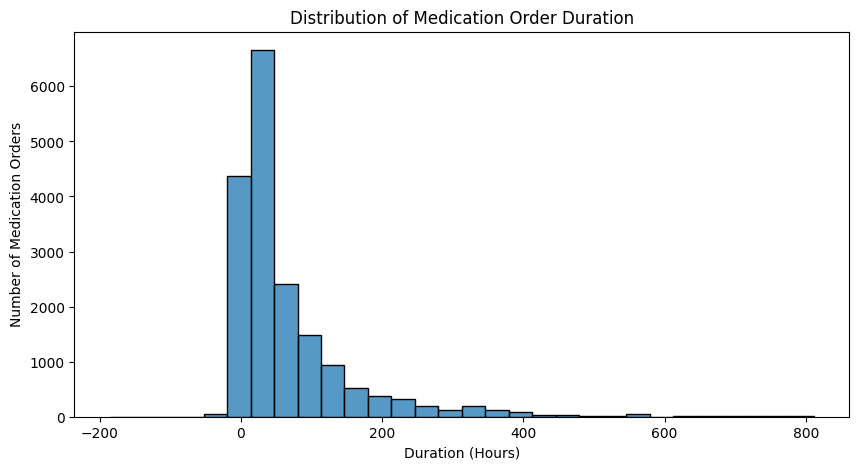

In [62]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=duration_data,
    x="duration_hours",
    bins=30
)

plt.title("Distribution of Medication Order Duration")
plt.xlabel("Duration (Hours)")
plt.ylabel("Number of Medication Orders")
plt.show()

In [63]:
print("Missing duration values:",prescriptions_clean["duration_hours"].isna().sum())
print("Negative duration values:",(prescriptions_clean["duration_hours"] < 0).sum())

Missing duration values: 14
Negative duration values: 753


In [64]:
duration_data = prescriptions_clean.dropna(
    subset=["duration_hours"]
)

In [65]:
negative_duration = prescriptions_clean[
    prescriptions_clean["duration_hours"] < 0
]

negative_duration[
    ["drug", "starttime", "stoptime", "duration_hours"]
].head(20)

,drug,starttime,stoptime,duration_hours
38,Insulin,2153-04-14 12:00:00,2153-04-14 11:00:00,-1.0
109,Insulin,2142-08-31 00:00:00,2142-08-30 23:00:00,-1.0
119,Insulin,2142-08-05 18:00:00,2142-08-05 17:00:00,-1.0
163,Insulin,2153-02-15 17:00:00,2153-02-15 16:00:00,-1.0
168,Insulin,2142-08-31 01:00:00,2142-08-31 00:00:00,-1.0
202,Insulin,2160-11-08 06:00:00,2160-11-08 05:00:00,-1.0
216,Insulin,2191-01-20 10:00:00,2191-01-20 09:00:00,-1.0
266,Insulin,2176-12-19 12:00:00,2176-12-19 11:00:00,-1.0
287,Insulin,2145-12-09 13:00:00,2145-12-09 12:00:00,-1.0
396,Neutra-Phos,2137-03-10 13:00:00,2137-03-10 12:00:00,-1.0


In [66]:
negative_duration["duration_hours"].describe()

count    753.000000
mean      -7.409031
std       17.347129
min     -186.000000
25%       -9.000000
50%       -1.000000
75%       -1.000000
max       -1.000000
Name: duration_hours, dtype: float64

In [67]:
negative_duration["drug"].value_counts().head(10)

drug
Insulin                    57
Furosemide                 37
5% Dextrose                34
Metoprolol Tartrate        30
0.9% Sodium Chloride       28
Potassium Chloride         25
Vancomycin                 21
Iso-Osmotic Dextrose       19
Metoprolol Succinate XL    17
Heparin                    16
Name: count, dtype: int64

In [68]:
duration_data = prescriptions_clean[
    prescriptions_clean["duration_hours"] >= 0
].copy()

In [69]:
print("Total records:", len(prescriptions_clean))
print("Valid duration records:", len(duration_data))
print("Missing duration:", prescriptions_clean["duration_hours"].isna().sum())
print("Negative duration:", (prescriptions_clean["duration_hours"] < 0).sum())

Total records: 18087
Valid duration records: 17320
Missing duration: 14
Negative duration: 753


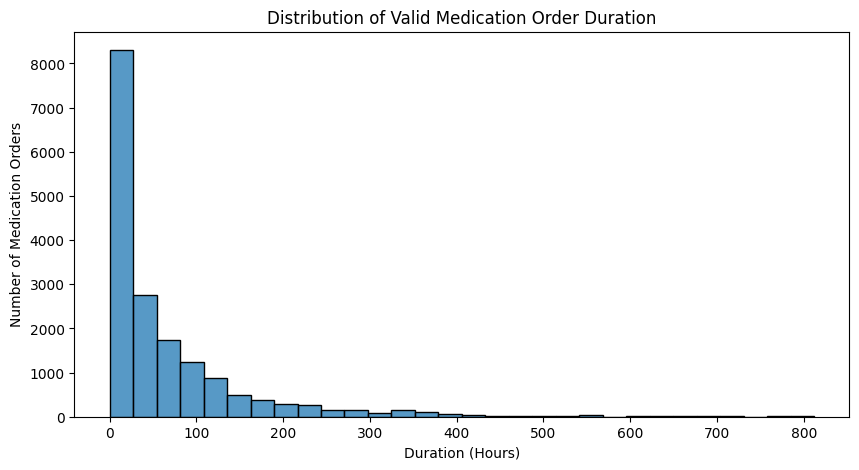

In [70]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=duration_data,
    x="duration_hours",
    bins=30
)

plt.title("Distribution of Valid Medication Order Duration")
plt.xlabel("Duration (Hours)")
plt.ylabel("Number of Medication Orders")
plt.show()

# Combining Core Tables

In [71]:
patient_admissions = admissions.merge(
    patients,
    on="subject_id",
    how="left"
)

In [72]:
patient_admissions.head()

,subject_id,hadm_id,admittime,dischtime,deathtime,admission_type,admit_provider_id,admission_location,discharge_location,insurance,...,marital_status,race,edregtime,edouttime,hospital_expire_flag,gender,anchor_age,anchor_year,anchor_year_group,dod
0,10004235,24181354,2196-02-24 14:38:00,2196-03-04 14:02:00,NaN,URGENT,P03YMR,TRANSFER FROM HOSPITAL,SKILLED NURSING FACILITY,Medicaid,...,SINGLE,BLACK/CAPE VERDEAN,2196-02-24 12:15:00,2196-02-24 17:07:00,0,M,47,2196,2014 - 2016,NaN
1,10009628,25926192,2153-09-17 17:08:00,2153-09-25 13:20:00,NaN,URGENT,P41R5N,TRANSFER FROM HOSPITAL,HOME HEALTH CARE,Medicaid,...,MARRIED,HISPANIC/LATINO - PUERTO RICAN,NaN,NaN,0,M,58,2153,2011 - 2013,NaN
2,10018081,23983182,2134-08-18 02:02:00,2134-08-23 19:35:00,NaN,URGENT,P233F6,TRANSFER FROM HOSPITAL,SKILLED NURSING FACILITY,Medicare,...,MARRIED,WHITE,2134-08-17 16:24:00,2134-08-18 03:15:00,0,M,79,2133,2011 - 2013,2134-10-28
3,10006053,22942076,2111-11-13 23:39:00,2111-11-15 17:20:00,2111-11-15 17:20:00,URGENT,P38TI6,TRANSFER FROM HOSPITAL,DIED,Medicaid,...,NaN,UNKNOWN,NaN,NaN,1,M,52,2111,2014 - 2016,2111-11-15
4,10031404,21606243,2113-08-04 18:46:00,2113-08-06 20:57:00,NaN,URGENT,P07HDB,TRANSFER FROM HOSPITAL,HOME,Other,...,WIDOWED,WHITE,NaN,NaN,0,F,82,2113,2014 - 2016,NaN


In [73]:
print("Rows:", len(patient_admissions))
print("Columns:", patient_admissions.shape[1])

Rows: 275
Columns: 21


In [74]:
print("Admissions before merge:", len(admissions))
print("Rows after merge:", len(patient_admissions))

Admissions before merge: 275
Rows after merge: 275


In [75]:
print("Unique patients:", patient_admissions["subject_id"].nunique())
print("Unique admissions:", patient_admissions["hadm_id"].nunique())

Unique patients: 100
Unique admissions: 275


Combine Admission and Diagnosis

In [76]:
admission_diagnoses = patient_admissions.merge(
    diagnosis_data,
    on=["subject_id", "hadm_id"],
    how="left"
)

In [77]:
print("Rows:", len(admission_diagnoses))
print("Columns:", admission_diagnoses.shape[1])

Rows: 4506
Columns: 25


In [78]:
admission_diagnoses.head()

,subject_id,hadm_id,admittime,dischtime,deathtime,admission_type,admit_provider_id,admission_location,discharge_location,insurance,...,hospital_expire_flag,gender,anchor_age,anchor_year,anchor_year_group,dod,seq_num,icd_code,icd_version,long_title
0,10004235,24181354,2196-02-24 14:38:00,2196-03-04 14:02:00,NaN,URGENT,P03YMR,TRANSFER FROM HOSPITAL,SKILLED NURSING FACILITY,Medicaid,...,0,M,47,2196,2014 - 2016,NaN,15,42731,9,Atrial fibrillation
1,10004235,24181354,2196-02-24 14:38:00,2196-03-04 14:02:00,NaN,URGENT,P03YMR,TRANSFER FROM HOSPITAL,SKILLED NURSING FACILITY,Medicaid,...,0,M,47,2196,2014 - 2016,NaN,5,51881,9,Acute respiratory failure
2,10004235,24181354,2196-02-24 14:38:00,2196-03-04 14:02:00,NaN,URGENT,P03YMR,TRANSFER FROM HOSPITAL,SKILLED NURSING FACILITY,Medicaid,...,0,M,47,2196,2014 - 2016,NaN,12,75169,9,"Other anomalies of gallbladder, bile ducts, an..."
3,10004235,24181354,2196-02-24 14:38:00,2196-03-04 14:02:00,NaN,URGENT,P03YMR,TRANSFER FROM HOSPITAL,SKILLED NURSING FACILITY,Medicaid,...,0,M,47,2196,2014 - 2016,NaN,13,4254,9,Other primary cardiomyopathies
4,10004235,24181354,2196-02-24 14:38:00,2196-03-04 14:02:00,NaN,URGENT,P03YMR,TRANSFER FROM HOSPITAL,SKILLED NURSING FACILITY,Medicaid,...,0,M,47,2196,2014 - 2016,NaN,21,2749,9,"Gout, unspecified"


In [79]:
print("Unique admissions:",admission_diagnoses["hadm_id"].nunique())
print("Unique patients:",admission_diagnoses["subject_id"].nunique())

Unique admissions: 275
Unique patients: 100


In [80]:
admission_diagnoses[
    [
        "subject_id",
        "hadm_id",
        "icd_code",
        "icd_version",
        "long_title",
        "seq_num"
    ]
].head(10)

,subject_id,hadm_id,icd_code,icd_version,long_title,seq_num
0,10004235,24181354,42731,9,Atrial fibrillation,15
1,10004235,24181354,51881,9,Acute respiratory failure,5
2,10004235,24181354,75169,9,"Other anomalies of gallbladder, bile ducts, an...",12
3,10004235,24181354,4254,9,Other primary cardiomyopathies,13
4,10004235,24181354,2749,9,"Gout, unspecified",21
5,10004235,24181354,2859,9,"Anemia, unspecified",25
6,10004235,24181354,570,9,Acute and subacute necrosis of liver,4
7,10004235,24181354,29900,9,"Autistic disorder, current or active state",10
8,10004235,24181354,486,9,"Pneumonia, organism unspecified",6
9,10004235,24181354,58389,9,"Nephritis and nephropathy, not specified as ac...",26


In [81]:
diagnoses_per_admission = (
    diagnosis_data
    .groupby("hadm_id")
    .size()
)

In [82]:
print("Average diagnoses per admission:",diagnoses_per_admission.mean())
print("Maximum diagnoses for one admission:",diagnoses_per_admission.max())

Average diagnoses per admission: 16.385454545454547
Maximum diagnoses for one admission: 39


In [83]:
diagnoses_per_admission.sort_values(
    ascending=False
).head(10)

hadm_id
22205327    39
29757856    39
22987108    39
27996267    39
24540843    39
20755971    38
28258130    38
23559586    38
28477280    37
20214994    36
dtype: int64

Combine Admissions, Diagnoses & Medications

In [84]:
final_data = admission_diagnoses.merge(
    prescriptions_clean,
    on=["subject_id", "hadm_id"],
    how="left"
)

In [85]:
print("Rows:", len(final_data))
print("Columns:", final_data.shape[1])

Rows: 384807
Columns: 33


In [86]:
final_data.head()

,subject_id,hadm_id,admittime,dischtime,deathtime,admission_type,admit_provider_id,admission_location,discharge_location,insurance,...,icd_version,long_title,starttime,stoptime,drug,drug_type,dose_val_rx,dose_unit_rx,route,duration_hours
0,10004235,24181354,2196-02-24 14:38:00,2196-03-04 14:02:00,NaN,URGENT,P03YMR,TRANSFER FROM HOSPITAL,SKILLED NURSING FACILITY,Medicaid,...,9,Atrial fibrillation,2196-02-26 07:00:00,2196-02-29 17:00:00,Insulin,MAIN,0,UNIT,SC,82.0
1,10004235,24181354,2196-02-24 14:38:00,2196-03-04 14:02:00,NaN,URGENT,P03YMR,TRANSFER FROM HOSPITAL,SKILLED NURSING FACILITY,Medicaid,...,9,Atrial fibrillation,2196-02-24 18:00:00,2196-02-28 08:00:00,Bag,BASE,1,BAG,DIALYS,86.0
2,10004235,24181354,2196-02-24 14:38:00,2196-03-04 14:02:00,NaN,URGENT,P03YMR,TRANSFER FROM HOSPITAL,SKILLED NURSING FACILITY,Medicaid,...,9,Atrial fibrillation,2196-02-26 10:00:00,2196-02-29 17:00:00,Bag,BASE,1,BAG,IV,79.0
3,10004235,24181354,2196-02-24 14:38:00,2196-03-04 14:02:00,NaN,URGENT,P03YMR,TRANSFER FROM HOSPITAL,SKILLED NURSING FACILITY,Medicaid,...,9,Atrial fibrillation,2196-03-03 08:00:00,2196-03-02 09:00:00,Lisinopril,MAIN,5,mg,PO/NG,-23.0
4,10004235,24181354,2196-02-24 14:38:00,2196-03-04 14:02:00,NaN,URGENT,P03YMR,TRANSFER FROM HOSPITAL,SKILLED NURSING FACILITY,Medicaid,...,9,Atrial fibrillation,2196-03-03 16:00:00,2196-03-04 18:00:00,Warfarin,MAIN,5,mg,PO/NG,26.0


In [87]:
len(final_data)

384807

In [88]:
print("Unique patients:", final_data["subject_id"].nunique())
print("Unique admissions:", final_data["hadm_id"].nunique())

Unique patients: 100
Unique admissions: 275


In [89]:
print("Unique medications:", final_data["drug"].nunique())
print("Unique diagnosis codes:", final_data["icd_code"].nunique())

Unique medications: 631
Unique diagnosis codes: 1472


In [90]:
final_data.columns.tolist()

['subject_id',
 'hadm_id',
 'admittime',
 'dischtime',
 'deathtime',
 'admission_type',
 'admit_provider_id',
 'admission_location',
 'discharge_location',
 'insurance',
 'language',
 'marital_status',
 'race',
 'edregtime',
 'edouttime',
 'hospital_expire_flag',
 'gender',
 'anchor_age',
 'anchor_year',
 'anchor_year_group',
 'dod',
 'seq_num',
 'icd_code',
 'icd_version',
 'long_title',
 'starttime',
 'stoptime',
 'drug',
 'drug_type',
 'dose_val_rx',
 'dose_unit_rx',
 'route',
 'duration_hours']

In [91]:
final_data = final_data[
    [
        "subject_id",
        "hadm_id",
        "admittime",
        "dischtime",
        "admission_type",
        "admission_location",
        "discharge_location",
        "insurance",
        "gender",
        "anchor_age",
        "marital_status",
        "race",
        "hospital_expire_flag",
        "icd_code",
        "long_title",
        "seq_num",
        "drug",
        "drug_type",
        "starttime",
        "stoptime",
        "route",
        "dose_val_rx",
        "dose_unit_rx"
    ]
]

In [92]:
print("Rows:", len(final_data))
print("Columns:", len(final_data.columns))

Rows: 384807
Columns: 23


In [93]:
final_data.head()

,subject_id,hadm_id,admittime,dischtime,admission_type,admission_location,discharge_location,insurance,gender,anchor_age,...,icd_code,long_title,seq_num,drug,drug_type,starttime,stoptime,route,dose_val_rx,dose_unit_rx
0,10004235,24181354,2196-02-24 14:38:00,2196-03-04 14:02:00,URGENT,TRANSFER FROM HOSPITAL,SKILLED NURSING FACILITY,Medicaid,M,47,...,42731,Atrial fibrillation,15,Insulin,MAIN,2196-02-26 07:00:00,2196-02-29 17:00:00,SC,0,UNIT
1,10004235,24181354,2196-02-24 14:38:00,2196-03-04 14:02:00,URGENT,TRANSFER FROM HOSPITAL,SKILLED NURSING FACILITY,Medicaid,M,47,...,42731,Atrial fibrillation,15,Bag,BASE,2196-02-24 18:00:00,2196-02-28 08:00:00,DIALYS,1,BAG
2,10004235,24181354,2196-02-24 14:38:00,2196-03-04 14:02:00,URGENT,TRANSFER FROM HOSPITAL,SKILLED NURSING FACILITY,Medicaid,M,47,...,42731,Atrial fibrillation,15,Bag,BASE,2196-02-26 10:00:00,2196-02-29 17:00:00,IV,1,BAG
3,10004235,24181354,2196-02-24 14:38:00,2196-03-04 14:02:00,URGENT,TRANSFER FROM HOSPITAL,SKILLED NURSING FACILITY,Medicaid,M,47,...,42731,Atrial fibrillation,15,Lisinopril,MAIN,2196-03-03 08:00:00,2196-03-02 09:00:00,PO/NG,5,mg
4,10004235,24181354,2196-02-24 14:38:00,2196-03-04 14:02:00,URGENT,TRANSFER FROM HOSPITAL,SKILLED NURSING FACILITY,Medicaid,M,47,...,42731,Atrial fibrillation,15,Warfarin,MAIN,2196-03-03 16:00:00,2196-03-04 18:00:00,PO/NG,5,mg


In [94]:
diagnosis_count = (
    diagnosis_data
    .groupby("hadm_id")
    .size()
    .reset_index(name="diagnosis_count")
)

In [95]:
diagnosis_count.head()

,hadm_id,diagnosis_count
0,20044587,8
1,20093566,32
2,20192635,18
3,20199380,5
4,20214994,36


In [96]:
medication_count = (
    prescriptions_clean
    .groupby("hadm_id")
    .size()
    .reset_index(name="medication_count")
)

In [97]:
medication_count.head()

,hadm_id,medication_count
0,20044587,86
1,20093566,45
2,20192635,45
3,20199380,59
4,20214994,227


# Summary

In [98]:
admission_summary = admissions.merge(
    diagnosis_count,
    on="hadm_id",
    how="left"
)

In [99]:
admission_summary = admission_summary.merge(
    medication_count,
    on="hadm_id",
    how="left"
)

Replace missing values with zero

In [100]:
admission_summary["diagnosis_count"] = (
    admission_summary["diagnosis_count"].fillna(0)
)

admission_summary["medication_count"] = (
    admission_summary["medication_count"].fillna(0)
)

In [101]:
admission_summary = admission_summary.merge(
    patients,
    on="subject_id",
    how="left"
)

Filtering to 15 columns

In [102]:
admission_summary = admission_summary[
    [
        "subject_id",
        "hadm_id",
        "admittime",
        "dischtime",
        "admission_type",
        "admission_location",
        "discharge_location",
        "insurance",
        "gender",
        "anchor_age",
        "marital_status",
        "race",
        "hospital_expire_flag",
        "diagnosis_count",
        "medication_count"
    ]
]

In [103]:
print("Rows:", len(admission_summary))
print("Columns:", len(admission_summary.columns))

Rows: 275
Columns: 15


In [104]:
print("Unique admissions:", admission_summary["hadm_id"].nunique())
print("Unique patients:", admission_summary["subject_id"].nunique())

Unique admissions: 275
Unique patients: 100


In [105]:
admission_summary.head()

,subject_id,hadm_id,admittime,dischtime,admission_type,admission_location,discharge_location,insurance,gender,anchor_age,marital_status,race,hospital_expire_flag,diagnosis_count,medication_count
0,10004235,24181354,2196-02-24 14:38:00,2196-03-04 14:02:00,URGENT,TRANSFER FROM HOSPITAL,SKILLED NURSING FACILITY,Medicaid,M,47,SINGLE,BLACK/CAPE VERDEAN,0,26,195.0
1,10009628,25926192,2153-09-17 17:08:00,2153-09-25 13:20:00,URGENT,TRANSFER FROM HOSPITAL,HOME HEALTH CARE,Medicaid,M,58,MARRIED,HISPANIC/LATINO - PUERTO RICAN,0,8,166.0
2,10018081,23983182,2134-08-18 02:02:00,2134-08-23 19:35:00,URGENT,TRANSFER FROM HOSPITAL,SKILLED NURSING FACILITY,Medicare,M,79,MARRIED,WHITE,0,19,59.0
3,10006053,22942076,2111-11-13 23:39:00,2111-11-15 17:20:00,URGENT,TRANSFER FROM HOSPITAL,DIED,Medicaid,M,52,NaN,UNKNOWN,1,10,63.0
4,10031404,21606243,2113-08-04 18:46:00,2113-08-06 20:57:00,URGENT,TRANSFER FROM HOSPITAL,HOME,Other,F,82,WIDOWED,WHITE,0,15,34.0


# KPIs

In [106]:
admission_summary["diagnosis_count"].mean()

16.385454545454547

In [107]:
admission_summary["medication_count"].mean()

65.77090909090909

Combined Healthcare Insights

In [108]:
avg_diagnoses = admission_summary["diagnosis_count"].mean()

print("Average diagnoses per admission:", round(avg_diagnoses, 2))

Average diagnoses per admission: 16.39


In [109]:
avg_medications = admission_summary["medication_count"].mean()

print("Average medication orders per admission:",
      round(avg_medications, 2))

Average medication orders per admission: 65.77


In [110]:
combined_summary = pd.DataFrame({
    "Metric": [
        "Total Patients",
        "Total Admissions",
        "Average Diagnoses per Admission",
        "Average Medication Orders per Admission"
    ],
    "Value": [
        admission_summary["subject_id"].nunique(),
        admission_summary["hadm_id"].nunique(),
        round(avg_diagnoses, 2),
        round(avg_medications, 2)
    ]
})

combined_summary

,Metric,Value
0,Total Patients,100.00
1,Total Admissions,275.00
2,Average Diagnoses per Admission,16.39
3,Average Medication Orders per Admission,65.77


Highest Diagnosis Volume

In [111]:
admission_summary[
    [
        "hadm_id",
        "subject_id",
        "diagnosis_count",
        "medication_count"
    ]
].sort_values(
    "diagnosis_count",
    ascending=False
).head(10)

,hadm_id,subject_id,diagnosis_count,medication_count
97,29757856,10014354,39,104.0
239,27996267,10040025,39,187.0
155,22987108,10007818,39,320.0
143,22205327,10029291,39,188.0
73,24540843,10037861,39,201.0
26,23559586,10003400,38,249.0
8,20755971,10038081,38,99.0
102,28258130,10039708,38,314.0
160,28477280,10031757,37,133.0
227,29276678,10035631,36,331.0


Highest Medication Volume

In [112]:
admission_summary[
    [
        "hadm_id",
        "subject_id",
        "diagnosis_count",
        "medication_count"
    ]
].sort_values(
    "medication_count",
    ascending=False
).head(10)

,hadm_id,subject_id,diagnosis_count,medication_count
13,23831430,10020740,24,348.0
227,29276678,10035631,36,331.0
155,22987108,10007818,39,320.0
102,28258130,10039708,38,314.0
26,23559586,10003400,38,249.0
201,28661809,10005817,25,241.0
27,20214994,10003400,36,227.0
70,25177949,10032725,23,214.0
234,23052851,10020306,28,212.0
79,28998349,10021487,35,211.0


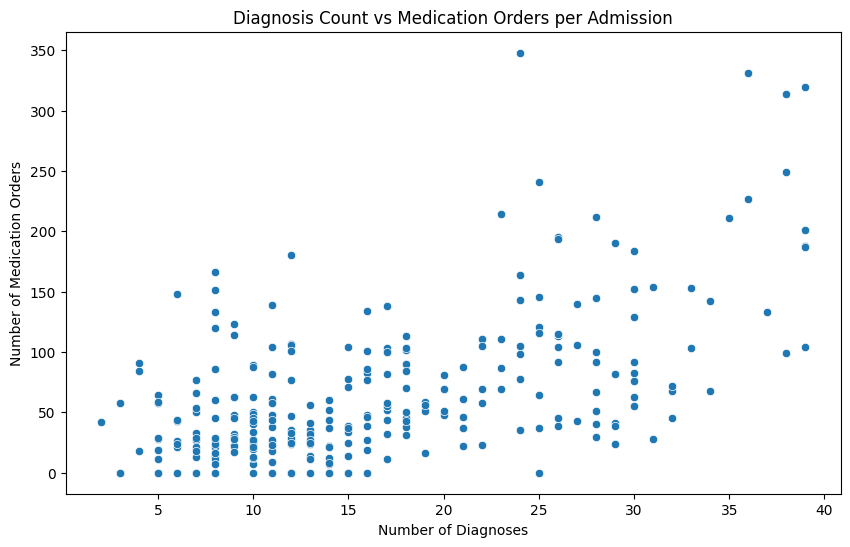

In [113]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=admission_summary,
    x="diagnosis_count",
    y="medication_count"
)

plt.title("Diagnosis Count vs Medication Orders per Admission")
plt.xlabel("Number of Diagnoses")
plt.ylabel("Number of Medication Orders")
plt.show()

In [114]:
correlation = admission_summary[
    ["diagnosis_count", "medication_count"]
].corr().iloc[0, 1]

print("Correlation:", round(correlation, 2))

Correlation: 0.59


# SQL Database Setup

In [115]:
import sqlite3
from pathlib import Path

Database Location

In [116]:
DB_PATH = Path(r"D:\Ashraf\Projects\MIMIC-IV Healthcare Analytics\Data\mimic.db")

Connect to SQLite

In [117]:
conn = sqlite3.connect(DB_PATH)

In [118]:
patients.to_sql(
    "patients",
    conn,
    if_exists="replace",
    index=False
)

100

In [119]:
admissions.to_sql(
    "admissions",
    conn,
    if_exists="replace",
    index=False
)

275

In [120]:
diagnoses.to_sql(
    "diagnoses_icd",
    conn,
    if_exists="replace",
    index=False
)

4506

In [121]:
d_icd_diagnoses.to_sql(
    "d_icd_diagnoses",
    conn,
    if_exists="replace",
    index=False
)

109775

In [122]:
prescriptions.to_sql(
    "prescriptions",
    conn,
    if_exists="replace",
    index=False
)

18087

In [123]:
tables = pd.read_sql_query(
    """
    SELECT name
    FROM sqlite_master
    WHERE type='table'
    """,
    conn
)

tables

,name
0,patients
1,admissions
2,diagnoses_icd
3,d_icd_diagnoses
4,prescriptions


In [124]:
for table in [
    "patients",
    "admissions",
    "diagnoses_icd",
    "d_icd_diagnoses",
    "prescriptions"
]:
    count = pd.read_sql_query(
        f"SELECT COUNT(*) AS count FROM {table}",
        conn
    )
    
    print(table, ":", count.iloc[0]["count"])

patients : 100
admissions : 275
diagnoses_icd : 4506
d_icd_diagnoses : 109775
prescriptions : 18087


In [128]:
# Create final Power BI dataset

primary_diagnosis = (
    diagnosis_data[diagnosis_data["seq_num"] == 1]
    [["hadm_id", "long_title"]]
    .rename(columns={"long_title": "primary_diagnosis"})
)

final_powerbi = admission_summary.merge(
    primary_diagnosis,
    on="hadm_id",
    how="left"
)

final_powerbi.to_csv(
    "../Data/admission_summary.csv",
    index=False
)

print("Rows:", final_powerbi.shape[0])
print("Columns:", final_powerbi.shape[1])

Rows: 275
Columns: 16


In [129]:
print(final_powerbi.columns.tolist())

['subject_id', 'hadm_id', 'admittime', 'dischtime', 'admission_type', 'admission_location', 'discharge_location', 'insurance', 'gender', 'anchor_age', 'marital_status', 'race', 'hospital_expire_flag', 'diagnosis_count', 'medication_count', 'primary_diagnosis']
